<a href="https://colab.research.google.com/github/tanvi1911/Multiple_Regression_Analysis_on_Diabetes_Dataset/blob/main/Multiple_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

import plotly.express as px
import plotly.graph_objects as go

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [6]:
# Load all CSV files
import glob

files = glob.glob("data/preprocessed/*.csv")

dfs = [pd.read_csv(f, sep=",", engine="python") for f in files]

df = pd.concat(dfs, ignore_index=True)

# Drop accidental extra column if present
df = df.loc[:, ~df.columns.str.contains(";")]

print(df.shape)
print(df.columns)
display(df.head())

(309392, 8)
Index(['time', 'glucose', 'calories', 'heart_rate', 'steps', 'basal_rate',
       'bolus_volume_delivered', 'carb_input'],
      dtype='str')


,time,glucose,calories,heart_rate,steps,basal_rate,bolus_volume_delivered,carb_input
0,2018-06-13T18:40:00,332.0,6.3595,82.322835,34.0,0.091667,0.0,0.0
1,2018-06-13T18:45:00,326.0,7.7280,83.740157,0.0,0.091667,0.0,0.0
2,2018-06-13T18:50:00,330.0,4.7495,80.525180,0.0,0.091667,0.0,0.0
3,2018-06-13T18:55:00,324.0,6.3595,89.129032,20.0,0.091667,0.0,0.0
4,2018-06-13T19:00:00,306.0,5.1520,92.495652,0.0,0.075000,0.0,0.0


In [13]:
# Convert time column to datetime
df["time"] = pd.to_datetime(df["time"])

# Ensure numeric columns are numeric
numeric_cols = [
    "glucose",
    "calories",
    "heart_rate",
    "steps",
    "basal_rate",
    "bolus_volume_delivered",
    "carb_input"
]

df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric)

# Check types
df.dtypes

time                      datetime64[us]
glucose                          float64
calories                         float64
heart_rate                       float64
steps                            float64
basal_rate                       float64
bolus_volume_delivered           float64
carb_input                       float64
patient_id                           str
dtype: object

In [14]:
# Check missing values
missing = df.isnull().sum()

print(missing)

time                      285156
glucose                   285156
calories                  285156
heart_rate                285156
steps                     285156
basal_rate                285156
bolus_volume_delivered    285156
carb_input                285156
patient_id                     0
dtype: int64


In [15]:
# Drop rows that are completely empty
df = df.dropna(how="all")

# Check missing values again
missing = df.isnull().sum()

print(df.shape)
print(missing)

(309392, 9)
time                      285156
glucose                   285156
calories                  285156
heart_rate                285156
steps                     285156
basal_rate                285156
bolus_volume_delivered    285156
carb_input                285156
patient_id                     0
dtype: int64


In [16]:
# Sort data by time
df = df.sort_values("time")

# Reset index
df = df.reset_index(drop=True)

df.head()

,time,glucose,calories,heart_rate,steps,basal_rate,bolus_volume_delivered,carb_input,patient_id
0,2018-06-13 18:40:00,332.0,6.3595,82.322835,34.0,0.091667,0.0,0.0,preprocessed\HUPA0001P
1,2018-06-13 18:45:00,326.0,7.7280,83.740157,0.0,0.091667,0.0,0.0,preprocessed\HUPA0001P
2,2018-06-13 18:50:00,330.0,4.7495,80.525180,0.0,0.091667,0.0,0.0,preprocessed\HUPA0001P
3,2018-06-13 18:55:00,324.0,6.3595,89.129032,20.0,0.091667,0.0,0.0,preprocessed\HUPA0001P
4,2018-06-13 19:00:00,306.0,5.1520,92.495652,0.0,0.075000,0.0,0.0,preprocessed\HUPA0001P


In [19]:
import os

dfs = []

for f in files:
    patient_id = os.path.basename(f).replace(".csv", "")
    
    temp = pd.read_csv(f, sep=",", engine="python")
    temp["patient_id"] = patient_id
    
    dfs.append(temp)

df = pd.concat(dfs, ignore_index=True)

# Drop accidental extra column if present
df = df.loc[:, ~df.columns.str.contains(";")]

In [20]:
df.head()

,time,glucose,calories,heart_rate,steps,basal_rate,bolus_volume_delivered,carb_input,patient_id
0,2018-06-13T18:40:00,332.0,6.3595,82.322835,34.0,0.091667,0.0,0.0,HUPA0001P
1,2018-06-13T18:45:00,326.0,7.7280,83.740157,0.0,0.091667,0.0,0.0,HUPA0001P
2,2018-06-13T18:50:00,330.0,4.7495,80.525180,0.0,0.091667,0.0,0.0,HUPA0001P
3,2018-06-13T18:55:00,324.0,6.3595,89.129032,20.0,0.091667,0.0,0.0,HUPA0001P
4,2018-06-13T19:00:00,306.0,5.1520,92.495652,0.0,0.075000,0.0,0.0,HUPA0001P


In [23]:
print(df["patient_id"].nunique())

25


In [24]:
print(len(files))

25


In [25]:
# Create future glucose target (30 minutes ahead)

df["glucose_future"] = (
    df.groupby("patient_id")["glucose"]
    .shift(-6)
)

df[["time", "glucose", "glucose_future"]].head(10)

,time,glucose,glucose_future
0,2018-06-13T18:40:00,332.0,312.0
1,2018-06-13T18:45:00,326.0,293.0
2,2018-06-13T18:50:00,330.0,303.0
3,2018-06-13T18:55:00,324.0,293.0
4,2018-06-13T19:00:00,306.0,271.0
5,2018-06-13T19:05:00,313.0,270.0
6,2018-06-13T19:10:00,312.0,255.0
7,2018-06-13T19:15:00,293.0,221.0
8,2018-06-13T19:20:00,303.0,242.0
9,2018-06-13T19:25:00,293.0,232.0


In [26]:
# Remove rows without future glucose
df = df.dropna(subset=["glucose_future"])

print(df.shape)

(24194, 10)


In [28]:
# Re-convert time column to datetime
df["time"] = pd.to_datetime(df["time"])

In [29]:
# Create time-based features
df["hour"] = df["time"].dt.hour
df["minute"] = df["time"].dt.minute
df["day_of_week"] = df["time"].dt.dayofweek

df[["time", "hour", "minute", "day_of_week"]].head()

,time,hour,minute,day_of_week
0,2018-06-13 18:40:00,18,40,2
1,2018-06-13 18:45:00,18,45,2
2,2018-06-13 18:50:00,18,50,2
3,2018-06-13 18:55:00,18,55,2
4,2018-06-13 19:00:00,19,0,2


In [30]:
# Create lag features (previous glucose values)

df["glucose_lag_1"] = df.groupby("patient_id")["glucose"].shift(1)
df["glucose_lag_2"] = df.groupby("patient_id")["glucose"].shift(2)
df["glucose_lag_3"] = df.groupby("patient_id")["glucose"].shift(3)

df[["glucose", "glucose_lag_1", "glucose_lag_2", "glucose_lag_3"]].head(10)

,glucose,glucose_lag_1,glucose_lag_2,glucose_lag_3
0,332.0,NaN,NaN,NaN
1,326.0,332.0,NaN,NaN
2,330.0,326.0,332.0,NaN
3,324.0,330.0,326.0,332.0
4,306.0,324.0,330.0,326.0
5,313.0,306.0,324.0,330.0
6,312.0,313.0,306.0,324.0
7,293.0,312.0,313.0,306.0
8,303.0,293.0,312.0,313.0
9,293.0,303.0,293.0,312.0


In [31]:
# Remove rows with missing lag values
df = df.dropna(subset=[
    "glucose_lag_1",
    "glucose_lag_2",
    "glucose_lag_3"
])

print(df.shape)

(24173, 16)


In [ ]:
# Define model input features (X) and prediction target (y)

features = [
    "glucose",
    "calories",
    "heart_rate",
    "steps",
    "basal_rate",
    "bolus_volume_delivered",
    "carb_input",
    "hour",
    "minute",
    "day_of_week",
    "glucose_lag_1",
    "glucose_lag_2",
    "glucose_lag_3"
]

target = "glucose_future"

X = df[features]
y = df[target]

print(X.shape)
print(y.shape)

(24173, 13)
(24173,)


In [ ]:
# Split dataset into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(19338, 13)
(4835, 13)
(19338,)
(4835,)


In [34]:
# Train a baseline linear regression model

from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [35]:
# Generate predictions and evaluate model performance

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 16.36609729734082
MSE: 593.4564933097672
RMSE: 24.360962487343706
R²: 0.8888321695471014


In [36]:
# Sort dataset by patient and time to preserve chronological order

df = df.sort_values(by=["patient_id", "time"])

print(df[["patient_id", "time"]].head())

  patient_id                time
3  HUPA0001P 2018-06-13 18:55:00
4  HUPA0001P 2018-06-13 19:00:00
5  HUPA0001P 2018-06-13 19:05:00
6  HUPA0001P 2018-06-13 19:10:00
7  HUPA0001P 2018-06-13 19:15:00


In [97]:
# Split data by patient_id (80% patients for training, 20% for testing)

import numpy as np

patient_ids = df["patient_id"].dropna().unique().to_numpy().copy()

np.random.seed(42)
np.random.shuffle(patient_ids)

split_index = int(len(patient_ids) * 0.8)

train_patients = patient_ids[:split_index]
test_patients = patient_ids[split_index:]

train_df = df[df["patient_id"].isin(train_patients)].copy()
test_df = df[df["patient_id"].isin(test_patients)].copy()

print("Train patients:", len(train_patients))
print("Test patients:", len(test_patients))
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Overlap:", set(train_patients) & set(test_patients))

Train patients: 5
Test patients: 2
Train shape: (17150, 16)
Test shape: (7023, 16)
Overlap: set()


In [98]:
# Create X and y for time-based training and testing sets

X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(17150, 13)
(7023, 13)
(17150,)
(7023,)


In [99]:
# Retrain linear regression model using time-based split

from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [100]:
# Evaluate model performance using time-based test set

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 18.59887808191599
MSE: 831.5102443060467
RMSE: 28.83591934213381
R²: 0.8724253656902948


In [101]:
# Scale features using StandardScaler (fit only on training data)

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print(X_train_scaled.shape)
print(X_test_scaled.shape)

(17150, 13)
(7023, 13)


In [102]:
# Retrain linear regression model using scaled features

model_scaled = LinearRegression()

model_scaled.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [103]:
# Evaluate scaled linear regression model performance

y_pred_scaled = model_scaled.predict(X_test_scaled)

mae_scaled = mean_absolute_error(y_test, y_pred_scaled)
mse_scaled = mean_squared_error(y_test, y_pred_scaled)
rmse_scaled = np.sqrt(mse_scaled)
r2_scaled = r2_score(y_test, y_pred_scaled)

print("Scaled MAE:", mae_scaled)
print("Scaled MSE:", mse_scaled)
print("Scaled RMSE:", rmse_scaled)
print("Scaled R²:", r2_scaled)

Scaled MAE: 18.598878081915984
Scaled MSE: 831.5102443060446
Scaled RMSE: 28.83591934213377
Scaled R²: 0.8724253656902952


In [104]:
# Train Random Forest regression model

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_scaled, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [105]:
# Evaluate Random Forest model performance

y_pred_rf = rf_model.predict(X_test_scaled)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("RF MAE:", mae_rf)
print("RF MSE:", mse_rf)
print("RF RMSE:", rmse_rf)
print("RF R²:", r2_rf)

RF MAE: 19.064618587975893
RF MSE: 746.3520484332196
RF RMSE: 27.319444511798178
RF R²: 0.8854907798224045


In [106]:
# Display feature importance from Random Forest model

import pandas as pd

feature_importance = pd.DataFrame({
    "feature": features,
    "importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

print(feature_importance)

                   feature  importance
0                  glucose    0.883464
12           glucose_lag_3    0.035272
2               heart_rate    0.012404
10           glucose_lag_1    0.011569
11           glucose_lag_2    0.011149
7                     hour    0.009998
4               basal_rate    0.009849
1                 calories    0.009632
9              day_of_week    0.005870
8                   minute    0.005301
3                    steps    0.003444
5   bolus_volume_delivered    0.001205
6               carb_input    0.000843


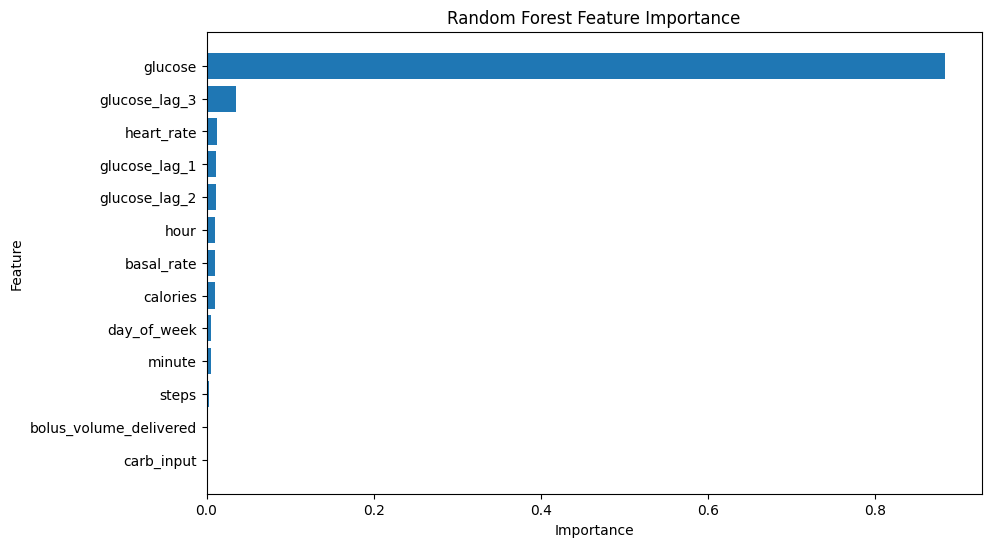

In [107]:
# Plot feature importance from Random Forest

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["feature"],
    feature_importance["importance"]
)

plt.gca().invert_yaxis()

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [108]:
# Create feature set without current glucose

features_no_current = [
    "calories",
    "heart_rate",
    "steps",
    "basal_rate",
    "bolus_volume_delivered",
    "carb_input",
    "hour",
    "minute",
    "day_of_week",
    "glucose_lag_1",
    "glucose_lag_2",
    "glucose_lag_3"
]

X_train_nc = train_df[features_no_current]
X_test_nc = test_df[features_no_current]

print(X_train_nc.shape)
print(X_test_nc.shape)

(17150, 12)
(7023, 12)


In [109]:
# Scale reduced feature set (without current glucose)

scaler_nc = StandardScaler()

X_train_nc_scaled = scaler_nc.fit_transform(X_train_nc)
X_test_nc_scaled = scaler_nc.transform(X_test_nc)

print(X_train_nc_scaled.shape)
print(X_test_nc_scaled.shape)

(17150, 12)
(7023, 12)


In [110]:
# Train Random Forest model without current glucose feature

rf_model_nc = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model_nc.fit(X_train_nc_scaled, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [111]:
# Evaluate Random Forest without current glucose feature

y_pred_rf_nc = rf_model_nc.predict(X_test_nc_scaled)

mae_rf_nc = mean_absolute_error(y_test, y_pred_rf_nc)
mse_rf_nc = mean_squared_error(y_test, y_pred_rf_nc)
rmse_rf_nc = np.sqrt(mse_rf_nc)
r2_rf_nc = r2_score(y_test, y_pred_rf_nc)

print("RF (no current glucose) MAE:", mae_rf_nc)
print("RF (no current glucose) MSE:", mse_rf_nc)
print("RF (no current glucose) RMSE:", rmse_rf_nc)
print("RF (no current glucose) R²:", r2_rf_nc)

RF (no current glucose) MAE: 22.800368656337277
RF (no current glucose) MSE: 990.513672625275
RF (no current glucose) RMSE: 31.472427180395144
RF (no current glucose) R²: 0.8480302312217544


In [112]:
# Compare model performance across experiments

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Random Forest (no glucose)"
    ],
    "RMSE": [
        rmse,
        rmse_rf,
        rmse_rf_nc
    ],
    "R²": [
        r2,
        r2_rf,
        r2_rf_nc
    ]
})

print(results)

                        Model       RMSE        R²
0           Linear Regression  28.835919  0.872425
1               Random Forest  27.319445  0.885491
2  Random Forest (no glucose)  31.472427  0.848030


In [113]:
# Tune Random Forest hyperparameters using GridSearchCV

from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid,
    cv=3,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train)

print("Best parameters:", grid_search.best_params_)

Best parameters: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}


In [114]:
# Train final Random Forest model using best hyperparameters

best_rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_split=2,
    random_state=42,
    n_jobs=-1
)

best_rf_model.fit(X_train_scaled, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [115]:
# Evaluate tuned Random Forest model

y_pred_best_rf = best_rf_model.predict(X_test_scaled)

mae_best_rf = mean_absolute_error(y_test, y_pred_best_rf)
mse_best_rf = mean_squared_error(y_test, y_pred_best_rf)
rmse_best_rf = np.sqrt(mse_best_rf)
r2_best_rf = r2_score(y_test, y_pred_best_rf)

print("Tuned RF MAE:", mae_best_rf)
print("Tuned RF MSE:", mse_best_rf)
print("Tuned RF RMSE:", rmse_best_rf)
print("Tuned RF R²:", r2_best_rf)

Tuned RF MAE: 18.929941424845982
Tuned RF MSE: 739.3630407064735
Tuned RF RMSE: 27.191230952394807
Tuned RF R²: 0.8865630698044377


In [116]:
model_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Random Forest (no glucose)",
        "Random Forest (tuned)"
    ],
    "RMSE": [
        31.208514,
        28.498487,
        32.998658,
        rmse_best_rf
    ],
    "R²": [
        0.854498,
        0.878670,
        0.837327,
        r2_best_rf
    ]
})

print(model_results)

                        Model       RMSE        R²
0           Linear Regression  31.208514  0.854498
1               Random Forest  28.498487  0.878670
2  Random Forest (no glucose)  32.998658  0.837327
3       Random Forest (tuned)  27.191231  0.886563


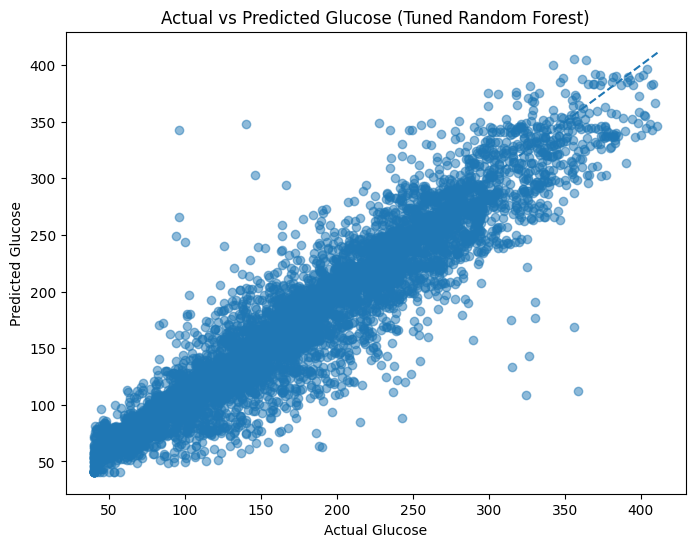

In [117]:
# Plot Actual vs Predicted values for tuned Random Forest

import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    y_pred_best_rf,
    alpha=0.5
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Glucose")
plt.ylabel("Predicted Glucose")
plt.title("Actual vs Predicted Glucose (Tuned Random Forest)")

plt.show()

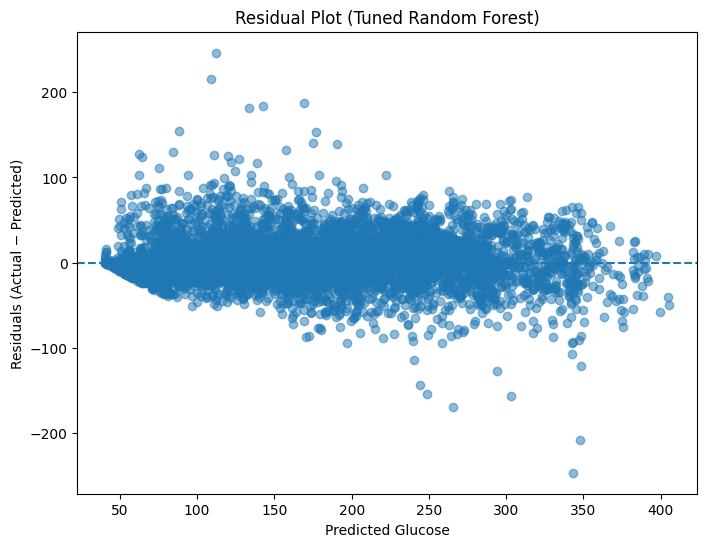

In [118]:
# Residual plot

residuals = y_test - y_pred_best_rf

plt.figure(figsize=(8,6))

plt.scatter(
    y_pred_best_rf,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Glucose")
plt.ylabel("Residuals (Actual − Predicted)")
plt.title("Residual Plot (Tuned Random Forest)")

plt.show()

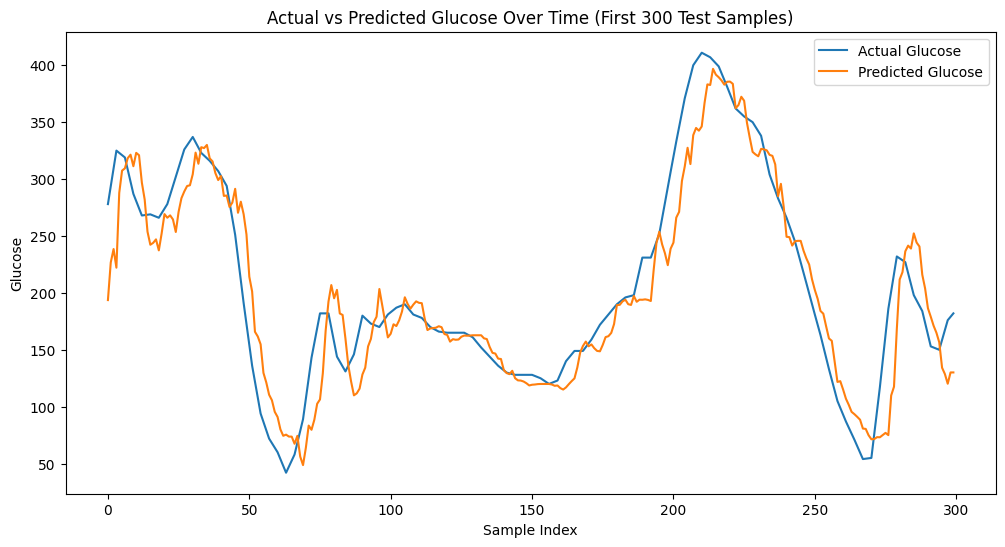

In [119]:
# Plot actual and predicted glucose values over sample index

plt.figure(figsize=(12, 6))

plt.plot(y_test.values[:300], label="Actual Glucose")
plt.plot(y_pred_best_rf[:300], label="Predicted Glucose")

plt.xlabel("Sample Index")
plt.ylabel("Glucose")
plt.title("Actual vs Predicted Glucose Over Time (First 300 Test Samples)")
plt.legend()

plt.show()

In [120]:
# Naive baseline on held-out patients
# Predict future glucose as current glucose

y_pred_naive = X_test["glucose"].values

mae_naive = mean_absolute_error(y_test, y_pred_naive)
mse_naive = mean_squared_error(y_test, y_pred_naive)
rmse_naive = np.sqrt(mse_naive)
r2_naive = r2_score(y_test, y_pred_naive)

print("Naive MAE:", mae_naive)
print("Naive MSE:", mse_naive)
print("Naive RMSE:", rmse_naive)
print("Naive R²:", r2_naive)

Naive MAE: 23.780196368259997
Naive MSE: 1094.592569369909
Naive RMSE: 33.08462738750293
Naive R²: 0.8320619045745757


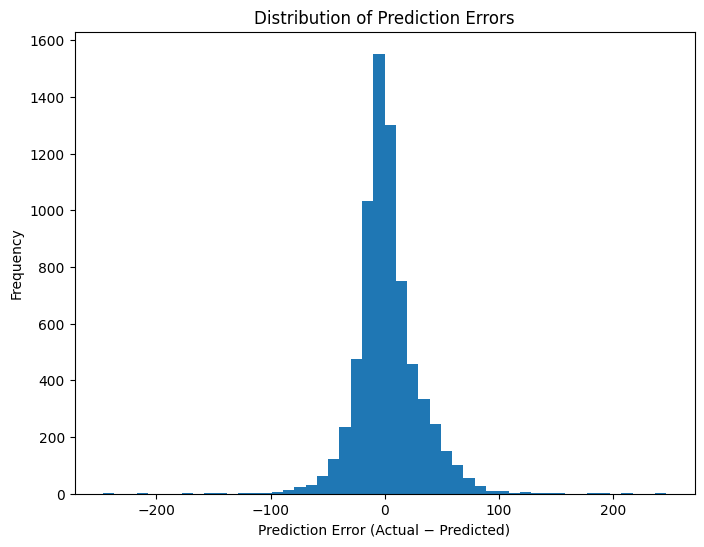

In [121]:
# Histogram of prediction errors

errors = y_test - y_pred_best_rf

plt.figure(figsize=(8,6))

plt.hist(
    errors,
    bins=50
)

plt.xlabel("Prediction Error (Actual − Predicted)")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors")

plt.show()

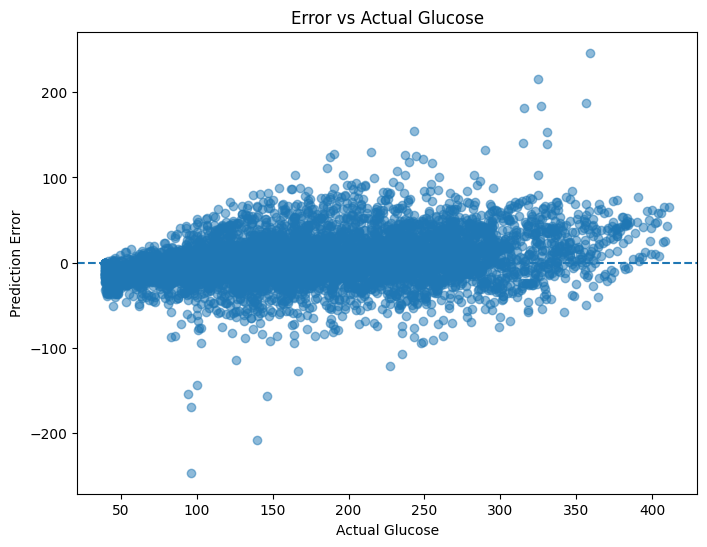

In [122]:
# Error vs actual glucose

errors = y_test - y_pred_best_rf

plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    errors,
    alpha=0.5
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Actual Glucose")
plt.ylabel("Prediction Error")
plt.title("Error vs Actual Glucose")

plt.show()

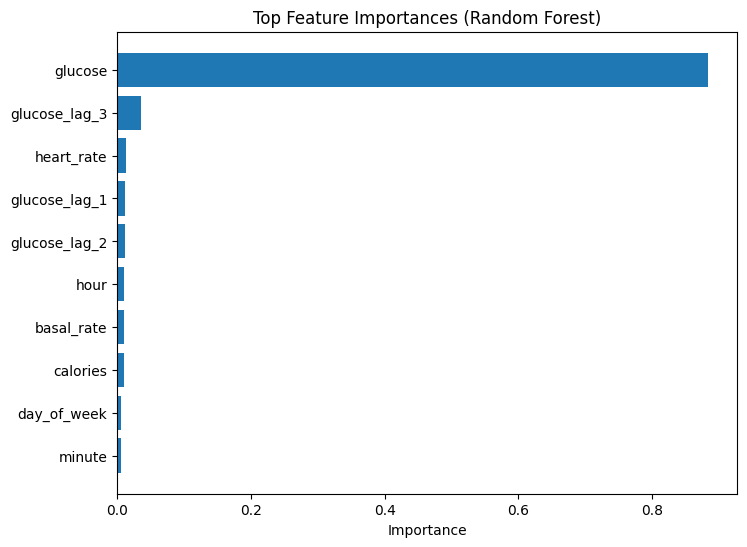

In [123]:
# Plot top feature importances

top_n = 10

plt.figure(figsize=(8,6))

plt.barh(
    feature_importance["feature"][:top_n][::-1],
    feature_importance["importance"][:top_n][::-1]
)

plt.xlabel("Importance")
plt.title("Top Feature Importances (Random Forest)")

plt.show()

In [124]:
import joblib

joblib.dump(best_rf_model, "tuned_random_forest_glucose_model.pkl")

['tuned_random_forest_glucose_model.pkl']

In [125]:
# Final summary table

final_results = pd.DataFrame({
    "Model": [
        "Naive Persistence",
        "Linear Regression",
        "Random Forest",
        "Random Forest (Tuned)"
    ],
    "RMSE": [
        rmse_naive,
        31.208514,
        28.498487,
        rmse_best_rf
    ],
    "R²": [
        r2_naive,
        0.854498,
        0.878670,
        r2_best_rf
    ]
})

final_results.sort_values(by="RMSE")

,Model,RMSE,R²
3,Random Forest (Tuned),27.191231,0.886563
2,Random Forest,28.498487,0.878670
1,Linear Regression,31.208514,0.854498
0,Naive Persistence,33.084627,0.832062
